# Analyze binary and ordinal responses

Fit a generalized partial credit model (GPCM) to ordinal item ratings.
The same workflow can start from binary responses or an ordinal
ideal-point model. The response model changes with the item and its scale.

## Choose a response model

Let $p$ index people and $j$ index items. In the equations below, $\theta_p$
is the person's score on the trait measured by item $j$ and $a_j>0$ is the
item's discrimination. $Y_{pj}$ denotes the observed response. Code 0
denotes the lowest category and $C_j$ is the number of categories for item $j$.

### Dichotomous IRT

For a binary item, the probability of response 1 is

$$
P(Y_{pj}=1)=c_j+(d_j-c_j)\operatorname{logistic}(a_j\theta_p-b_j),
\qquad \operatorname{logistic}(z)=\frac{1}{1+e^{-z}}.
$$

The intercept $b_j$ shifts the curve toward higher trait scores as it
increases. The limits $c_j$ and $d_j$ are the probabilities approached at
very low and very high scores. 1PL estimates a common $a_j=a$ and 2PL estimates
one $a_j$ per item. Both set $c_j=0$ and $d_j=1$. 3PL estimates $c_j$ and
fixes $d_j=1$. 4PL estimates both limits, with $0<c_j<d_j<1$.

### Generalized partial credit model (GPCM)

The worked example uses GPCM. The log weight of category $k$ is
$L_{pjk}=k\,a_j\theta_p+v_{jk}$. Its probability is

$$
P(Y_{pj}=k)=
\frac{e^{L_{pjk}}}{\sum_{h=0}^{C_j-1}e^{L_{pjh}}},
\qquad k=0,\ldots,C_j-1.
$$

The intercept $v_{jk}$ shifts the weight of category $k$ relative to the
reference category with $v_{j0}=0$. Higher categories receive more weight
relative to lower ones as $\theta_p$ increases. For a three-category item,
the log weights are $0$, $a_j\theta_p+v_{j1}$ and $2a_j\theta_p+v_{j2}$.

### Generalized graded unfolding model (GGUM)

GGUM gives higher categories more weight near the item's ideal point
$\delta_j$. For an item measuring one trait, define the scaled distance
$r_{pj}=a_j|\theta_p-\delta_j|$. The log weights are

$$
L_{pjk}=\log\cosh\!\left[(C_j-\tfrac12-k)r_{pj}\right]
        -a_j\sum_{h=0}^{k}\tau_{jh}.
$$

Here $\cosh(x)=(e^x+e^{-x})/2$. The category probabilities use the same
normalization over log weights as GPCM. The step parameter $\tau_{jh}$
enters the cumulative sum for every category $k\ge h$. The reference
step $\tau_{j0}$ is zero and the other steps are estimated. Because the
formula uses absolute distance, scores equally far above and below
$\delta_j$ give the same probabilities.
[Model details and priors](../models/single_items.md)

## Read the item design and responses

The GPCM example uses 50 simulated respondents answering 12 items that
measure one trait. Each design row names an item and the trait it measures.

In [1]:
import seaborn as sns

import pyfcirt as fc

sns.set_theme(style="ticks")

example = fc.load_example("simulated_mgpcm", model="GPCM", n_persons=50)
example.data.design.head(3)

,item_id,trait
0,I1,theta1
1,I2,theta1
2,I3,theta1


Each response row records one category for a person and item. This example
uses ordered labels 0, 1 and 2. The example bundle also declares these
categories, so the full scale is available even when a category is unobserved.

In [2]:
example.data.responses.frame.head(3)

,person_id,item_id,response
0,1,I1,0
1,1,I2,0
2,1,I3,0


To reuse the workflow with another model, replace the example-loading line
above. For binary responses with 1PL, use
`fc.load_example("simulated_mirt", model=fc.DichotomousIRT(kind="1PL"), n_persons=50)`.
For ordinal ideal-point responses, use
`fc.load_example("simulated_mggum", model="GGUM", n_persons=50)`.
The GGUM design adds `location_side` to specify the sign restriction for
an item's location.

## Check the prior predictions

Before fitting, examine whether the prior can produce the cumulative
category frequencies observed in I1. Each panel treats one category
threshold at a time. The shaded ranges reflect simulated responses under
the prior.
The plot labels the estimated calibrated event probability as CEP.

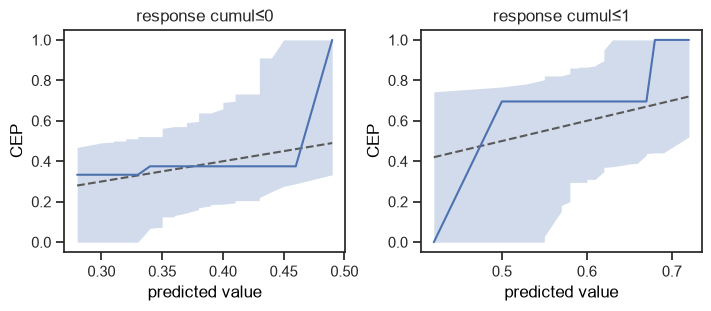

In [3]:
import arviz_plots as azp
import matplotlib.pyplot as plt

model = fc.Model().prepare(example.data)
prior = model.prior_predictive(draws=100, random_seed=42)
view = fc.predictive_view(prior, item="I1")
azp.plot_ppc_pava(
    view,
    group="prior_predictive",
    data_type=view.attrs["data_type"],
    figure_kwargs={"figsize": (7, 3), "layout": "constrained"},
)
plt.show()

## Fit the model

The displayed estimates use four chains with 1,000 warmup iterations
and 1,000 retained draws per chain. [Estimation backend setup](../examples/estimation_backends.md)

In [4]:
model.fit(draws=1000, tune=1000, chains=4, random_seed=43);

## Diagnose the chains

The maximum R-hat is 1.007, the smallest bulk and tail effective sample
sizes are 2,935 and 2,277, and there are zero divergences.

In [5]:
import arviz as az
import numpy as np

posterior = model.idata.posterior.to_dataset().reset_coords(drop=True)
with np.errstate(invalid="ignore", divide="ignore"):
    r_hat = az.rhat(posterior).max().to_array().max().item()
    bulk = az.ess(posterior, method="bulk").min().to_array().min().item()
    tail = az.ess(posterior, method="tail").min().to_array().min().item()

print(f"Max R-hat: {r_hat:.3f}")
print(f"Min bulk / tail ESS: {bulk:.0f} / {tail:.0f}")
print("Divergences:", int(model.idata.sample_stats.diverging.sum()))

Max R-hat: 1.007
Min bulk / tail ESS: 2935 / 2277
Divergences: 0


The density and rank plots compare chains for respondent 1's trait score.
The displayed rank-uniformity test has p near 0.28.

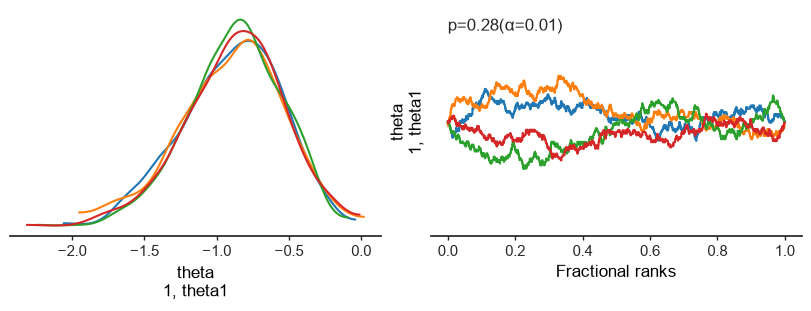

In [6]:
with sns.color_palette("tab10"):
    azp.plot_rank_dist(
        model.idata,
        var_names=["theta"],
        coords={"person": [1]},
        compact=False,
        backend="matplotlib",
        figure_kwargs={"figsize": (8, 3), "layout": "constrained"},
    )
    plt.show()

## Read item parameters

The I1 loading has a posterior mean of 1.27. The category 0 intercept is
fixed at zero, so its posterior SD and 95% interval are blank. The remaining
rows describe uncertainty for the estimated category intercepts.

In [7]:
estimates = model.coef(items=["I1"], kind="stats", round_to=2)
estimates.style.format(precision=2, na_rep="").format_index(na_rep="")

## Check the predicted ratings

Compare the fitted and observed cumulative category frequencies for I1.
The diagonal marks agreement. A curve above it means that the cumulative
event occurs more often than the model predicts.

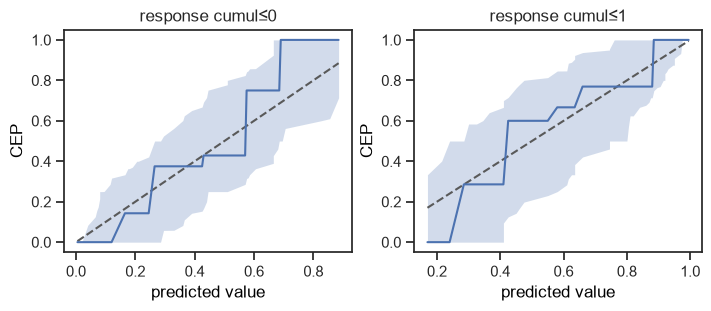

In [8]:
predictions = model.posterior_predictive(draws=200, random_seed=44)
view = fc.predictive_view(predictions, item="I1")
azp.plot_ppc_pava(
    view,
    data_type=view.attrs["data_type"],
    figure_kwargs={"figsize": (7, 3), "layout": "constrained"},
)
plt.show()

The Pearson check compares observed and replicated discrepancies. Its
posterior predictive p-value (PPP) is the share of replicated discrepancies
at least as large as the observed one. The table shows the check for two
items with 50 answered ratings each.

In [9]:
check = model.chi_ppp(
    predictions=predictions,
    items=["I1", "I2"],
    groupby="item",
)
check[["PPP", "n_obs"]].to_dataframe().round({"PPP": 3})

,PPP,n_obs
item,,
I1,0.420,50
I2,0.745,50


## Read score precision

The information plot shows how sharply the fitted item likelihood
distinguishes nearby scores. Each dot represents one respondent. Greater
information means the likelihood changes more sharply around that score.

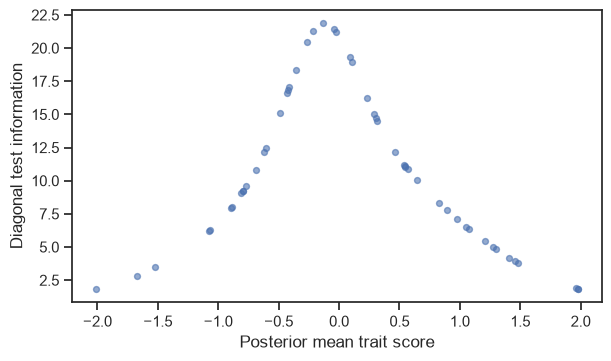

In [10]:
info = model.information(progressbar=False)
scores = model.idata["posterior"]["theta"].mean(("chain", "draw"))
trait = scores.trait.values[0]
fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
ax.scatter(
    scores.sel(trait=trait),
    info["test_information"].sel(trait=trait, trait_aux=trait),
    s=18,
    alpha=0.6,
)
ax.set(
    xlabel="Posterior mean trait score",
    ylabel="Diagonal test information",
)
plt.show()

Empirical reliability summarizes how well the scores distinguish people on
the trait, relative to their posterior uncertainty.

In [11]:
reliability = model.reliability()["reliability"].to_series()
reliability.round(3).to_frame("Reliability")

,Reliability
trait,
theta1,0.876


The [joint workflow](joint_workflow.ipynb) shows how to fit item and
forced-choice responses in the same model.